In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine,load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [3]:
wine = load_wine()
X = wine.data
y = wine.target

feat_names = wine.feature_names
target_names = wine.target_names

print("Original dataset shape: ", X.shape)
print("Target shape: ", y.shape)
print("Feature names: ", feat_names)
print("Target names: ", target_names)

Original dataset shape:  (178, 13)
Target shape:  (178,)
Feature names:  ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target names:  ['class_0' 'class_1' 'class_2']


In [5]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_reduced = pca.fit_transform(x_scaled)
print("Original: ", X.shape)
print("Reduced",X_reduced.shape)

Original:  (178, 13)
Reduced (178, 2)


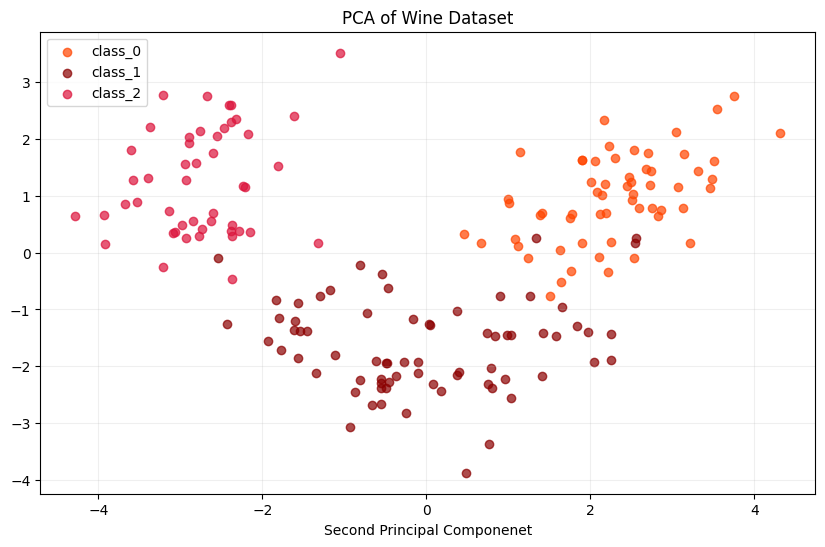

In [7]:
wine_colors = ['orangered', 'darkred','crimson']
plt.figure(figsize=(10, 6))

for class_num, color, target_name in zip([0,1,2], wine_colors, target_names):
  plt.scatter(X_reduced[y==class_num, 0], X_reduced[y==class_num,1], color=color, label=target_name, alpha=0.7)

plt.title("PCA of Wine Dataset")
plt.xlabel("First Principal Componenet")
plt.xlabel("Second Principal Componenet")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [8]:
print("Principal component loadings:")
print(pca.components_)
print("Shape of principal components: ", pca.components_.shape)

Principal component loadings:
[[ 0.1443294  -0.24518758 -0.00205106 -0.23932041  0.14199204  0.39466085
   0.4229343  -0.2985331   0.31342949 -0.0886167   0.29671456  0.37616741
   0.28675223]
 [ 0.48365155  0.22493093  0.31606881 -0.0105905   0.299634    0.06503951
  -0.00335981  0.02877949  0.03930172  0.52999567 -0.27923515 -0.16449619
   0.36490283]]
Shape of principal components:  (2, 13)


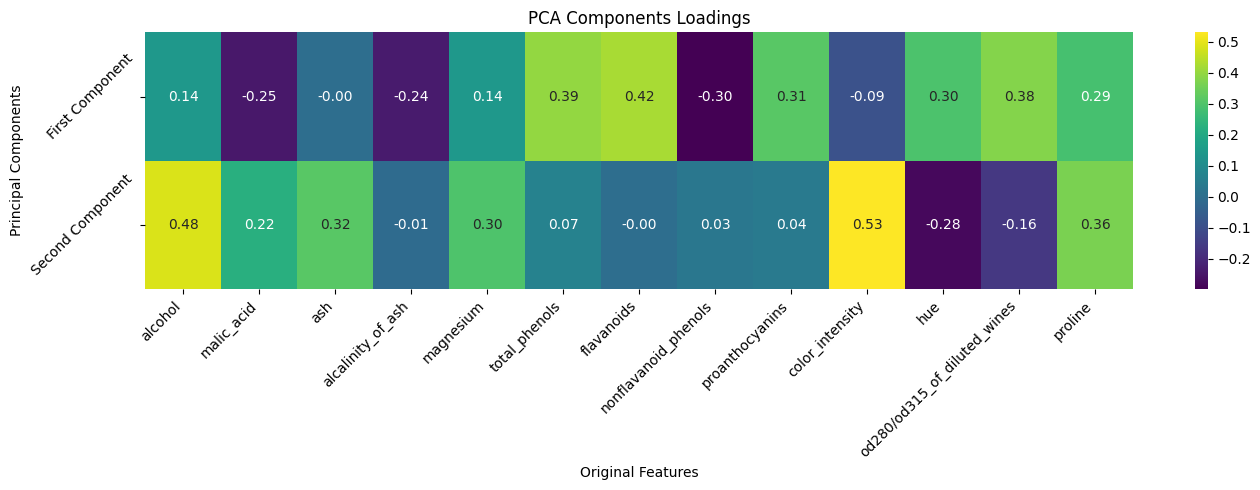

In [11]:
plt.figure(figsize=(14, 5))

sns.heatmap(pca.components_, annot=True, fmt='.2f', cmap='viridis', xticklabels=feat_names, yticklabels=['First Component', 'Second Component'])

plt.title('PCA Components Loadings')
plt.xlabel('Original Features')
plt.ylabel('Principal Components')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [12]:
print("Explained Variance: ")
print(pca.explained_variance_)
print("\nExplained Variance Ratio: ")
print(pca.explained_variance_ratio_)

Explained Variance: 
[4.73243698 2.51108093]

Explained Variance Ratio: 
[0.36198848 0.1920749 ]


In [13]:
pca_3 = PCA(n_components=0.96)
X_reduced_96 = pca_3.fit_transform(x_scaled)
print("Number of components selected: ",pca_3.n_components_)
print("Total explained variance: ", np.sum(pca_3.explained_variance_ratio_))
print("Reduced dataset shape: ", X_reduced_96.shape)

Number of components selected:  10
Total explained variance:  0.9616971684450643
Reduced dataset shape:  (178, 10)


# Random Forest

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [15]:
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/cpu-performance/machine.data"
)

columns = [
    "vendor", "model", "MYCT", "MMIN", "MMAX",
    "CACH", "CHMIN", "CHMAX", "PRP", "ERP"
]

data = pd.read_csv(url, names=columns)

print("First five rows:")
print(data.head())

First five rows:
    vendor    model  MYCT  MMIN   MMAX  CACH  CHMIN  CHMAX  PRP  ERP
0  adviser    32/60   125   256   6000   256     16    128  198  199
1   amdahl   470v/7    29  8000  32000    32      8     32  269  253
2   amdahl  470v/7a    29  8000  32000    32      8     32  220  253
3   amdahl  470v/7b    29  8000  32000    32      8     32  172  253
4   amdahl  470v/7c    29  8000  16000    32      8     16  132  132


In [16]:
print("\\nDataset shape:", data.shape)
print("\\nMissing values:")
print(data.isnull().sum())

\nDataset shape: (209, 10)
\nMissing values:
vendor    0
model     0
MYCT      0
MMIN      0
MMAX      0
CACH      0
CHMIN     0
CHMAX     0
PRP       0
ERP       0
dtype: int64


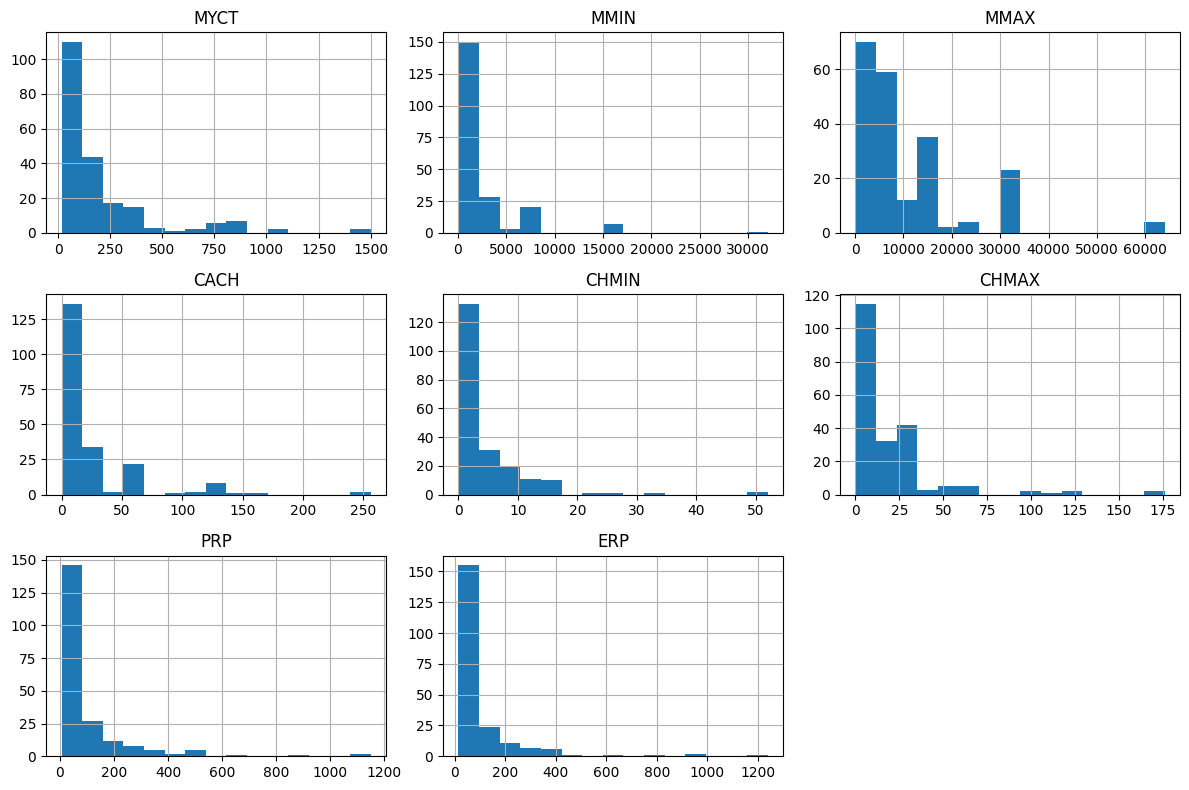

In [17]:
data.hist(figsize=(12, 8), bins=15)
plt.tight_layout()
plt.show()

In [18]:
# Correlation between numerical columns
correlation = data.select_dtypes(include=np.number).corr()

print("\\nCorrelation with PRP:")
print(correlation["PRP"].sort_values(ascending=False))

\nCorrelation with PRP:
PRP      1.000000
ERP      0.966472
MMAX     0.863004
MMIN     0.794931
CACH     0.662641
CHMIN    0.608903
CHMAX    0.605209
MYCT    -0.307099
Name: PRP, dtype: float64


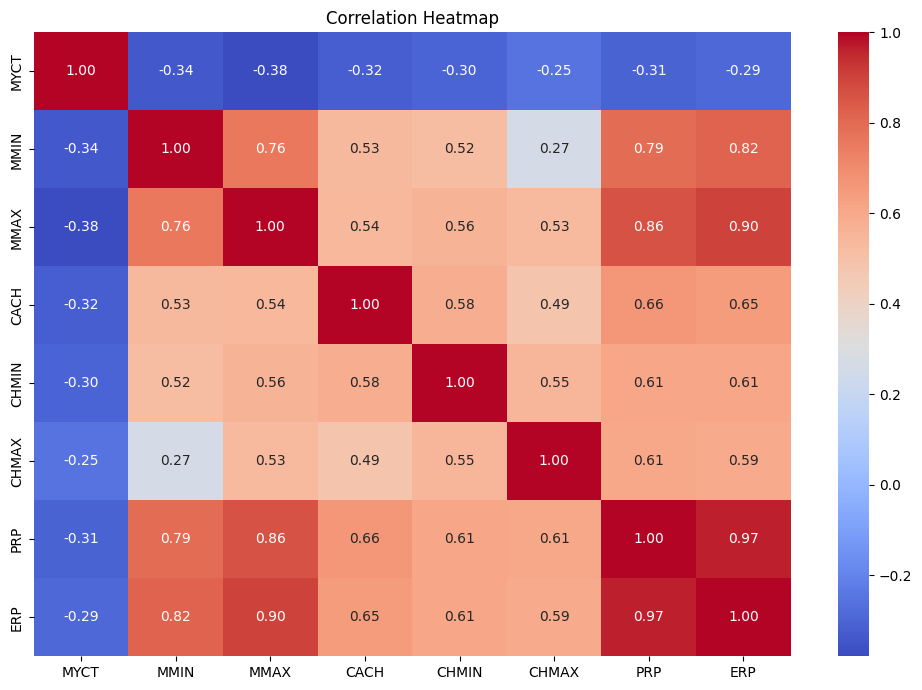

In [19]:
plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [20]:
# Predict PRP using hardware characteristics
X = data.drop(columns=["PRP", "ERP", "vendor", "model"])
y = data["PRP"]

print("\\nFeatures:")
print(X.head())

print("\\nTarget:")
print(y.head())

\nFeatures:
   MYCT  MMIN   MMAX  CACH  CHMIN  CHMAX
0   125   256   6000   256     16    128
1    29  8000  32000    32      8     32
2    29  8000  32000    32      8     32
3    29  8000  32000    32      8     32
4    29  8000  16000    32      8     16
\nTarget:
0    198
1    269
2    220
3    172
4    132
Name: PRP, dtype: int64


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

\nTraining samples: 167
Testing samples: 42


In [22]:
forest_reg = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

forest_reg.fit(X_train, y_train)

y_train_pred = forest_reg.predict(X_train)

In [23]:
train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred)
)

train_r2 = r2_score(y_train, y_train_pred)

print("\\nInitial Training Results")
print("Training RMSE:", round(train_rmse, 2))
print("Training R2 Score:", round(train_r2, 4))

\nInitial Training Results
Training RMSE: 28.94
Training R2 Score: 0.9564
